# Introduction to Python Data Structures

In this notebook we are going through python's most used **data** structures: *Lists*, Dictionaries, Sets, NumPy Arrays.

# QUICK FEATURES OVERVIEW
  - `resources`
  - insert cells and types + features
  - runtime/kernel ops + running order
  - file system
  - shortcuts

In [ ]:
# Creating a list
my_list = [1, 2, 3, 4, 5]
print("Original list:", my_list)

Original list: [1, 2, 3, 4, 5]


Note that thanks to interactive running you can accelerate visualization/inspection of variable values, plots, ...

This means we can **bypass some standard python syntax!**

Example: don't need to explicitely print, last instruction of each cell is automatically returned and printed if not assigned!

In [1]:
#@title Bonus: HTML-styled textbox for highlighting content
from IPython.core.display import HTML
HTML("""
<div class="alert">
  <p>This is an alert box.<br><br>
  <b>Note:</b> in normal Jupyter Notebook is easier:

        <div class="alert alert-box alert-info">

        Here is my highlighted info box (skyblue background)!
        </div>
  </p>
</div>

<style>
.alert {
  padding: 20px;
  background-color: #f44336;
  color: white;
  margin-bottom: 15px;
}
</style>
""")

In [ ]:
# Lists can store elements of different types
mixed_list = [1, "Hello", 3.14, True]
print("Mixed list:", mixed_list)

# Lists are mutable: elements can be changed
my_list[0] = 10
print("Modified list:", my_list)

# Adding elements
my_list.append(6)  # Adds 6 at the end
print("After append:", my_list)

my_list.insert(2, 15)  # Inserts 15 at index 2
print("After insert:", my_list)

# Removing elements
my_list.remove(3)  # Removes the first occurrence of 3
print("After remove:", my_list)

popped_element = my_list.pop()  # Removes and returns the last element
print("After pop:", my_list, "| Popped element:", popped_element)

# List slicing
sub_list = my_list[1:4]  # Elements from index 1 to 3
print("Sliced list:", sub_list)

Mixed list: [1, 'Hello', 3.14, True]
Modified list: [10, 2, 3, 4, 5]
After append: [10, 2, 3, 4, 5, 6]
After insert: [10, 2, 15, 3, 4, 5, 6]
After remove: [10, 2, 15, 4, 5, 6]
After pop: [10, 2, 15, 4, 5] | Popped element: 6
Sliced list: [2, 15, 4]


### Math operations

In [ ]:
my_list + 1

TypeError: can only concatenate list (not "int") to list

In [ ]:
my_list + [1]

[10, 2, 15, 4, 5, 1]

In [ ]:
my_list_plus1 = []

for el in my_list:
  my_list_plus1.append(el + 1)

my_list_plus1

[11, 3, 16, 5, 6]

### List comprehension

This is a great feature of list objects!

It makes code:
 - more concise, and easier to read
 - run faster than loops
 - handle filtering and transformations more easily

In [ ]:
# List comprehension
squares = [x**2 for x in range(10)]
print("Squares:", squares)

# List comprehension with filtering
even_squares = [x**2 for x in range(10) if x % 2 == 0]
print("Even squares:", even_squares)

my_list_plus1 = [x+1 for x in my_list]
print("My list incremented by 1:", my_list_plus1)

Squares: [0, 1, 4, 9, 16, 25, 36, 49, 64, 81]
Even squares: [0, 4, 16, 36, 64]
My list incremented by 1: [11, 3, 16, 5, 6]


### Caveat: Lists passed by reference

Beware that lists are passed by reference in functions/assignation.

This implies they are edited directly (*in place*). Make sure you **use `.copy()` to avoid unexpected modifications!**

In [ ]:
def increment_list(_list1):
  res = _list1 # REMOVE .copy() # important! without copy we modify first argument in place!
  for i, value in enumerate(res):
    res[i] = value + 1
    # res[i] += 1 # shortcut
  return res

temp_list = [1, 2, 3, 4, 5]

print(f"List before increment:\n{temp_list=}")
print("\nIncrement result:", increment_list(temp_list))
print(f"\nList after increment:\n{temp_list=}")

List before increment:
temp_list=[1, 2, 3, 4, 5]

Increment result: [2, 3, 4, 5, 6]

List after increment:
temp_list=[2, 3, 4, 5, 6]


## Dictionaries

Dictionaries are useful to store key-value pairs, hence enforcing a more readable/meaningful structure.

 - keys must be immutable types (e.g., strings, numbers, tuples).
 - values can be of any type

In [ ]:
# Creating a dictionary
my_dict = {"name": "Alice", "age": 25, "city": "New York"}
print("Dictionary:", my_dict)

# Accessing values
name = my_dict["name"]
print("Name:", name)

# Adding or updating key-value pairs
my_dict["email"] = "alice@example.com"  # Adds a new key-value pair
my_dict["age"] = 26  # Updates the value of the existing key 'age'
print("Updated dictionary:", my_dict)

# Removing key-value pairs
del my_dict["city"]
print("After deletion:", my_dict)

# Dictionary comprehension
squared_numbers = {x: x**2 for x in range(5)}
print("Squared numbers dictionary:", squared_numbers)

Dictionary: {'name': 'Alice', 'age': 25, 'city': 'New York'}
Name: Alice
Updated dictionary: {'name': 'Alice', 'age': 26, 'city': 'New York', 'email': 'alice@example.com'}
After deletion: {'name': 'Alice', 'age': 26, 'email': 'alice@example.com'}
Squared numbers dictionary: {0: 0, 1: 1, 2: 4, 3: 9, 4: 16}


Accessing elements by referencing their key value works fine if we know the content of the dictionary.

**Sometimes we do not know elements in advance, or they might have been changed throughout our script (especially keys)!**

When that is the case, we will get an error if trying to retrive an element that is not present.

In such cases we need functionalities to inspect dictionary content and retrieve it more safely:
 - `.keys()` and `.values()` --> inspect all keys and values
 - `.get(key, default_value)` --> search for `.key` and return its value if found, otherwise return `default_value`

In [ ]:
# get keys
print("Dictionary keys:", my_dict.keys())

# get values
print("Dictionary values:", my_dict.values())

# safer lookup
alice_job = my_dict.get("job", "unemployed")
print("What is Alice occupation? -->", alice_job)

Dictionary keys: dict_keys(['name', 'age', 'email'])
Dictionary values: dict_values(['Alice', 26, 'alice@example.com'])
What is Alice occupation? --> unemployed


## Sets

A set is an **unordered collection** of **unique elements**. Unlike lists or dictionaries, sets **do not allow duplicate values** and offer efficient membership testing.

- Fast lookup operations (`O(1)` on average)
- Automatically removes duplicate values
- Supports mathematical set operations (union, intersection, difference)


In [ ]:

# Creating a set
my_set = {1, 2, 3, 4, 5}
my_set_alternative = set([1, 2, 3, 4, 5])
print("Set:", my_set_alternative)
print("Set:", my_set)

# Sets store unique elements
# Adding elements
my_set.add(6)
print("After add:", my_set)

# Removing elements
my_set.remove(3)
print("After remove:", my_set)

Set: {1, 2, 3, 4, 5}
Set: {1, 2, 3, 4, 5}
After add: {1, 2, 3, 4, 5, 6}
After remove: {1, 2, 4, 5, 6}


On top of automatically getting rid of duplicates, **sets are great if you need to compare unique elements of different collection.**

In [ ]:
# Set operations
another_set = {4, 5, 6, 7, 8}
union_set = my_set.union(another_set)
print("Union:", union_set)

intersection_set = my_set.intersection(another_set)
print("Intersection:", intersection_set)

difference_set = my_set.difference(another_set)
print("Difference:", difference_set)

Union: {1, 2, 4, 5, 6, 7, 8}
Intersection: {4, 5, 6}
Difference: {1, 2}


In [ ]:
another_set.difference(my_set)

{7, 8}

In [ ]:
# this works also with other collections

set_list_intersection = my_set.intersection(my_list) # Lists
print("Intersection between set and list:", set_list_intersection)

set_dict_union = my_set.union(my_dict.values())
print("Union between set and dict values:", set_dict_union)

Intersection between set and list: {2, 4, 5}
Union between set and dict values: {1, 2, 'Alice', 4, 5, 6, 'alice@example.com', 26}


## NumPy Arrays

NumPy provides the **ndarray (N-dimensional array)**, which is an efficient, memory-friendly alternative to Python lists for numerical computations.

**Advantages Over Lists**
- **Fixed-type storage**: unlike lists, all elements must have the same data type
- **Efficient memory usage**: uses contiguous memory blocks for fast access
- **Vectorized operations**: supports fast mathematical computations without loops

In [ ]:
import numpy as np

# Creating a NumPy array
np_array = np.array([6, 5, 4, 3, 2, 1])
print("NumPy array:", np_array)

# NumPy arrays are mutable and store elements of the same type
np_array[0] = 10
print("\nModified NumPy array:", np_array)

# Creating arrays with specific values
zeros_array = np.zeros(5)
print("\nZeros array:", zeros_array)

ones_array = np.ones((2, 3))
print("Ones array:\n", ones_array)

# Arithmetic operations
array_sum = np_array + np_array
print("\nSum:", array_sum)

array_product = np_array * 2
print("\nProduct:", array_product)

# Broadcasting
matrix = np.array([[1, 2, 3], [4, 5, 6]])
print("\nMatrix:\n", matrix)

successful_broadcast_sum = matrix + np_array[3:] # same for product
print("\nBroadcast sum:\n", successful_broadcast_sum)

failed_broadcast_sum = matrix + np_array
print("Broadcast sum:\n", failed_broadcast_sum)

NumPy array: [6 5 4 3 2 1]

Modified NumPy array: [10  5  4  3  2  1]

Zeros array: [0. 0. 0. 0. 0.]
Ones array:
 [[1. 1. 1.]
 [1. 1. 1.]]

Sum: [20 10  8  6  4  2]

Product: [20 10  8  6  4  2]

Matrix:
 [[1 2 3]
 [4 5 6]]

Broadcast sum:
 [[4 4 4]
 [7 7 7]]


ValueError: operands could not be broadcast together with shapes (2,3) (6,) 

In [ ]:
#@title Bonus: fix broadcasting error

### OPTION 1: keep matrix shape
print("Option 1: keep matrix shape")
# Reshape np_array to match the matrix shape
reshaped_array = np_array.reshape(2, 3)
print(f"{reshaped_array=}")

# Now broadcasting works
broadcast_sum = matrix + reshaped_array
print("Broadcast sum:\n", broadcast_sum)

# OPTION 2: keep array shape
print("\nOption 2: keep array shape")

print("Two alternatives based on how we reshape the matrix")
flat_matrix_byrow = matrix.ravel() # same as matrix.flatten()
flat_matrix_bycol = matrix.ravel(order='F') # same as matrix.flatten()
print(f"{flat_matrix_byrow=}\n{flat_matrix_bycol=}")

# Now broadcasting works
broadcast_sum_byrow = flat_matrix_byrow + np_array
broadcast_sum_bycol = flat_matrix_bycol + np_array
print("\nBroadcast sum by row:\n", broadcast_sum_byrow)
print("Broadcast sum by column:\n", broadcast_sum_bycol)

Option 1: keep matrix shape
reshaped_array=array([[10,  5,  4],
       [ 3,  2,  1]])
Broadcast sum:
 [[11  7  7]
 [ 7  7  7]]

Option 2: keep array shape
Two alternatives based on how we reshape the matrix
flat_matrix_byrow=array([1, 2, 3, 4, 5, 6])
flat_matrix_bycol=array([1, 4, 2, 5, 3, 6])

Broadcast sum by row:
 [11  7  7  7  7  7]
Broadcast sum by column:
 [11  9  6  8  5  7]


In [ ]:
#@title Takeaway message:
from IPython.core.display import HTML
HTML("""
<div class="alert">
  <p>
  <b>pay attention to shapes!</b>
  </p>
</div>

<style>
.alert {
  padding: 20px;
  background-color: #b8e1ff;
  color: #444545;
  margin-bottom: 15px;
}
</style>
""")

### Matrix product

In matrix multiplication, inner dimensions must match. If I have a matrix A of size (2,3) and a matrix B of size (3,3), I am allowed to multiply AxB but not BxA. This requirements come from the definition of a dot product:

> $ C(i,j) = \sum_{k=1}^N A(i,k) \cdot B(k,j)$

where the $(i,j)$th element of C is the scalar x scalar product between raw $A(i,:)$ and column $B(:,j)$ - with $k$ acting as silent index. In NumPy, this is

    np.dot(A,B)
    
or

    A.dot(B)

Often one wants to multiply matrix elements, i.e. element-wise multiplication:

$C(i,j) = A(i,j) * B(i,j)$

We saw that this "asterisk" operator works for vectors, we want the same for matrices, in nD - i.e. we want this to work also for nD NumPy arrays. Both multidimentional arrays must be of the exact same size, though. In NumPy,

- the "asterisk" $C(i,j) = A(i,j) * B(i,j)$) means element-by-element (element-wise) multiplication.
- the "dot" means dot product, or **inner product**, i.e. matrix multiplication. ($C(i,j) = \sum_{k=1}^N A(i,k) \cdot B(k,j)$)

### Structured arrays


A **structured array** is a NumPy array where each element is like a row in a database, with multiple named fields of different data types.

**Why Use Structured Arrays?**
- store **heterogeneous data** (e.g., IDs, names, and numeric values in one array)
- perform **fast, vectorized operations** on specific fields
- useful for **loading structured datasets** efficiently

In [ ]:
# Structured arrays
structured_array = np.array([(1, 'Alice', 25), (2, 'Bob', 30)],
                            dtype=[('id', 'i4'), ('name', 'U10'), ('age', 'i4')])
print("Structured array:", structured_array)

# Accessing structured array fields
names = structured_array['name']
print("Names:", names)

Structured array: [(1, 'Alice', 25) (2, 'Bob', 30)]
Names: ['Alice' 'Bob']


## Comparison: numpy vs. list

In [ ]:
# Performance comparison
import time

# Create a list of squares using for loop
def list_squares_for(n):
  my_list = []
  for i in range(n):
    my_list.append(i**2)
  return my_list

# Sum using for loop and edit
def lists_sum_for(_list1, _list2):
  res = _list1.copy() # important! without copy we modify first argument in place!
  for i, l2 in enumerate(_list2):
    res[i] += l2
  return res

# Sum using for loop and new list
def lists_sum_for(_list1, _list2):
  res = list()
  for l1, l2 in zip(_list1, _list2):
    res.append(l1+l2)
  return res

# Create a list of squares
def list_squares_comprehension(n):
    return [i**2 for i in range(n)]

# Create a NumPy array of squares
def numpy_squares(n):
    return np.arange(n)**2

# Comparing creation time
n = 1000000

# for
start_time = time.time()
list_squares_for(n)
list_time_for = time.time() - start_time

# comprehension
start_time = time.time()
list_squares_comprehension(n)
list_time_comprehension = time.time() - start_time

# numpy
start_time = time.time()
numpy_squares(n)
numpy_time = time.time() - start_time

print(f"List creation time (for loop): {list_time_for:.5f} seconds")
print(f"List creation time (comprehension): {list_time_comprehension:.5f} seconds")
print(f"NumPy array creation time: {numpy_time:.5f} seconds")

# Comparing vectorized operations
list1 = list(range(n))
list2 = list(range(n))

np_array1 = np.arange(n)
np_array2 = np.arange(n)

# List addition for
start_time = time.time()
list_sum_for = lists_sum_for(list1, list2)
list_op_time_for = time.time() - start_time

# List addition comprehension
start_time = time.time()
list_sum_comprehension = [x + y for x, y in zip(list1, list2)]
list_op_time_comprehension = time.time() - start_time

# NumPy array addition
start_time = time.time()
np_sum = np_array1 + np_array2
numpy_op_time = time.time() - start_time

# check same results: for vs comprehension
assert np.all(np.array(list_sum_for)==np.array(list_sum_comprehension)), f"""Check for vs. comprehension implementation!
Results do not match\n{list_sum_for[:5]=}\n{list_sum_comprehension[:5]=}"""

# check same results: list vs numpy
assert np.all(np.array(list_sum_for)==np_sum), f"""Check for vs. comprehension implementation!
Results do not match\n{list_sum_for[:5]=}\n{np_sum[:5]=}"""

print(f"\n\nList addition time (for loop, edit): {list_op_time_for:.5f} seconds")
print(f"List addition time (comprehension): {list_op_time_comprehension:.5f} seconds")
print(f"NumPy array addition time: {numpy_op_time:.5f} seconds")

List creation time (for loop): 0.09973 seconds
List creation time (comprehension): 0.08619 seconds
NumPy array creation time: 0.00268 seconds


List addition time (for loop, edit): 0.09624 seconds
List addition time (comprehension): 0.07812 seconds
NumPy array addition time: 0.00247 seconds


In [ ]:
key_sets = {}
my_set = {1, 2}
type(key_sets), type(my_set)

(dict, set)

In [ ]:
list(), dict(), set()

([], {}, set())

In [ ]:
[], {}, set()

([], {}, set())

In [ ]:
#@title Takeaway message:
from IPython.core.display import HTML
HTML("""
<div class="alert">
  <p>
   - numpy has a factor 10x (at least) improvement compared to list
   <br>
   - list comprehension performs similarly in creation, but has 2x boost in edit
  </p>
</div>

<style>
.alert {
  padding: 20px;
  background-color: #b8e1ff;
  color: #444545;
  margin-bottom: 15px;
}
</style>
""")

## Hands-on Exercise

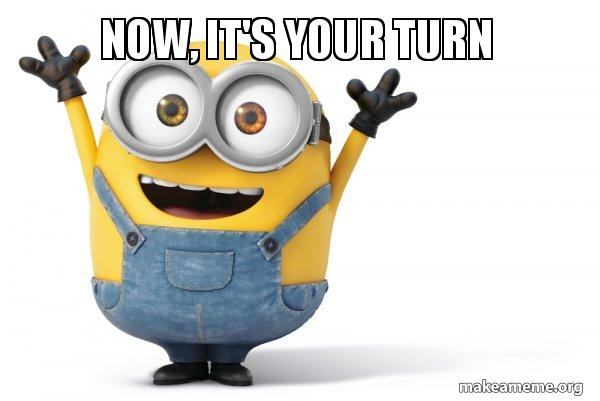

> Task:
 - given a list of numbers, create a new list containing the squares of even numbers lower than 100
 - now create a dictionary having the squares as values and their squared roots as keys
 - create two sets from keys and values, respectively, and check if some numbers appear both as keys and values
 - generate random numpy array and its max (google how to do it, if needed!)
    - find its max
    - transform it to list and do the same
    - compare runtimes
